# **Credit Risk  Machine Learning System**

In [1]:
# Libraries Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("/kaggle/input/datasets/laotse/credit-risk-dataset/credit_risk_dataset.csv")

In [3]:
print('Data Shape',data.shape)

Data Shape (32581, 12)


In [4]:
print('Missing Values:\n',data.isna().mean()*100)

Missing Values:
 person_age                    0.000000
person_income                 0.000000
person_home_ownership         0.000000
person_emp_length             2.747000
loan_intent                   0.000000
loan_grade                    0.000000
loan_amnt                     0.000000
loan_int_rate                 9.563856
loan_status                   0.000000
loan_percent_income           0.000000
cb_person_default_on_file     0.000000
cb_person_cred_hist_length    0.000000
dtype: float64


**Inferance**:
- missing values are present in 2 columns `person_emp_length` ~2.7% and `loan_int_rate` ~9.5%

In [5]:
print(f'Duplicate Values: {data.duplicated().sum()}')

Duplicate Values: 165


In [6]:
# Removing duplicate values:
data.drop_duplicates(inplace=True)
print('Duplicate Drops Succesfully!!')

Duplicate Drops Succesfully!!


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32416 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32416 non-null  int64  
 1   person_income               32416 non-null  int64  
 2   person_home_ownership       32416 non-null  object 
 3   person_emp_length           31529 non-null  float64
 4   loan_intent                 32416 non-null  object 
 5   loan_grade                  32416 non-null  object 
 6   loan_amnt                   32416 non-null  int64  
 7   loan_int_rate               29321 non-null  float64
 8   loan_status                 32416 non-null  int64  
 9   loan_percent_income         32416 non-null  float64
 10  cb_person_default_on_file   32416 non-null  object 
 11  cb_person_cred_hist_length  32416 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.2+ MB


In [8]:
# checking  class imbalance
data['loan_status'].value_counts()/len(data)*100

loan_status
0    78.13117
1    21.86883
Name: count, dtype: float64

**Inferance**:
- Target class moderately imbalance; class 0(~78%) only   1(21.86%)
- May need sampling

## **Splitting data in independent and dependent features.**

In [9]:
x = data.drop('loan_status',axis=1)
y = data['loan_status']

In [10]:
x.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
person_age,32416.0,27.747008,6.354100,20.00,23.00,26.00,30.00,144.00
person_income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.00,79218.00,6000000.00
person_emp_length,31529.0,4.790510,4.145490,0.00,2.00,4.00,7.00,123.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,29321.0,11.017265,3.241680,5.42,7.90,10.99,13.47,23.22
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.00,8.00,30.00


1. `person_age`:
- Mean age is ~27.76 years, with median (50%) at 26 years — confirms most borrowers are young adults.
- Max value is 144 years — this is clearly a data entry error/outlier (humanly impossible). Needs to be capped or removed.
- Min is 20 years, which makes sense as legal borrowing age.
- IQR (25%-75%) is 23-30 years, showing tight clustering of young borrowers.
2. `person_income`:
- Mean (~ 66,704) is much higher than the 75th percentile (~80,000), indicating strong right skew.
- Max is 6,000,000 — an extreme outlier (likely a data error or ultra-high net worth individual). This will severely distort the model.
- Min is 4,000 — very low income borrowers exist, which is a high-risk segment.
- High standard deviation (62,457) relative to mean confirms high variability.
Action required: Winsorization at 99th percentile or log transformation.
3. `person_emp_length`:
- Mean is ~4.79 years, median is 4 years — slight right skew.
- Max is 123 years — impossible value (data error). Needs capping.
- Min is 0 — includes students/unemployed, which is a high-risk group.
- 25th percentile is 2 years — many borrowers have short employment history.
4. `loan_amnt`:
- Mean (~ 9,665) and median (~8,000) are close — relatively symmetric distribution.
- Range: 500 to 35,000 — reasonable loan amounts.
No extreme outliers, but wide range suggests different loan purposes.
5. `loan_int_rate`:
- Mean (~ 11.04%) and median (~10.99%) are very close — near-normal distribution.
- Range: 5.42% to 23.22% — reflects different risk grades (A to G).
- Low std (3.07) indicates rates are well-clustered.
6. `loan_percent_income`:
- Mean (~0.17) — on average, borrowers request loans worth 17% of their income.
- Max is 0.83 — some borrowers request loans worth 83% of income (very high risk).
- Min is 0 — some very small loans relative to income.
- Right-skewed; higher values indicate higher default risk.
7. `cb_person_cred_hist_length`:
- Mean (~5.82 years), median (4 years) — right-skewed.
- Range: 2 to 30 years.
- Min is 2 years — even the shortest credit history is 2 years (no brand-new borrowers).
- Longer credit history generally indicates lower risk.

In [11]:
data[data['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


- Need Capping.

##  **Univariate Analysis**

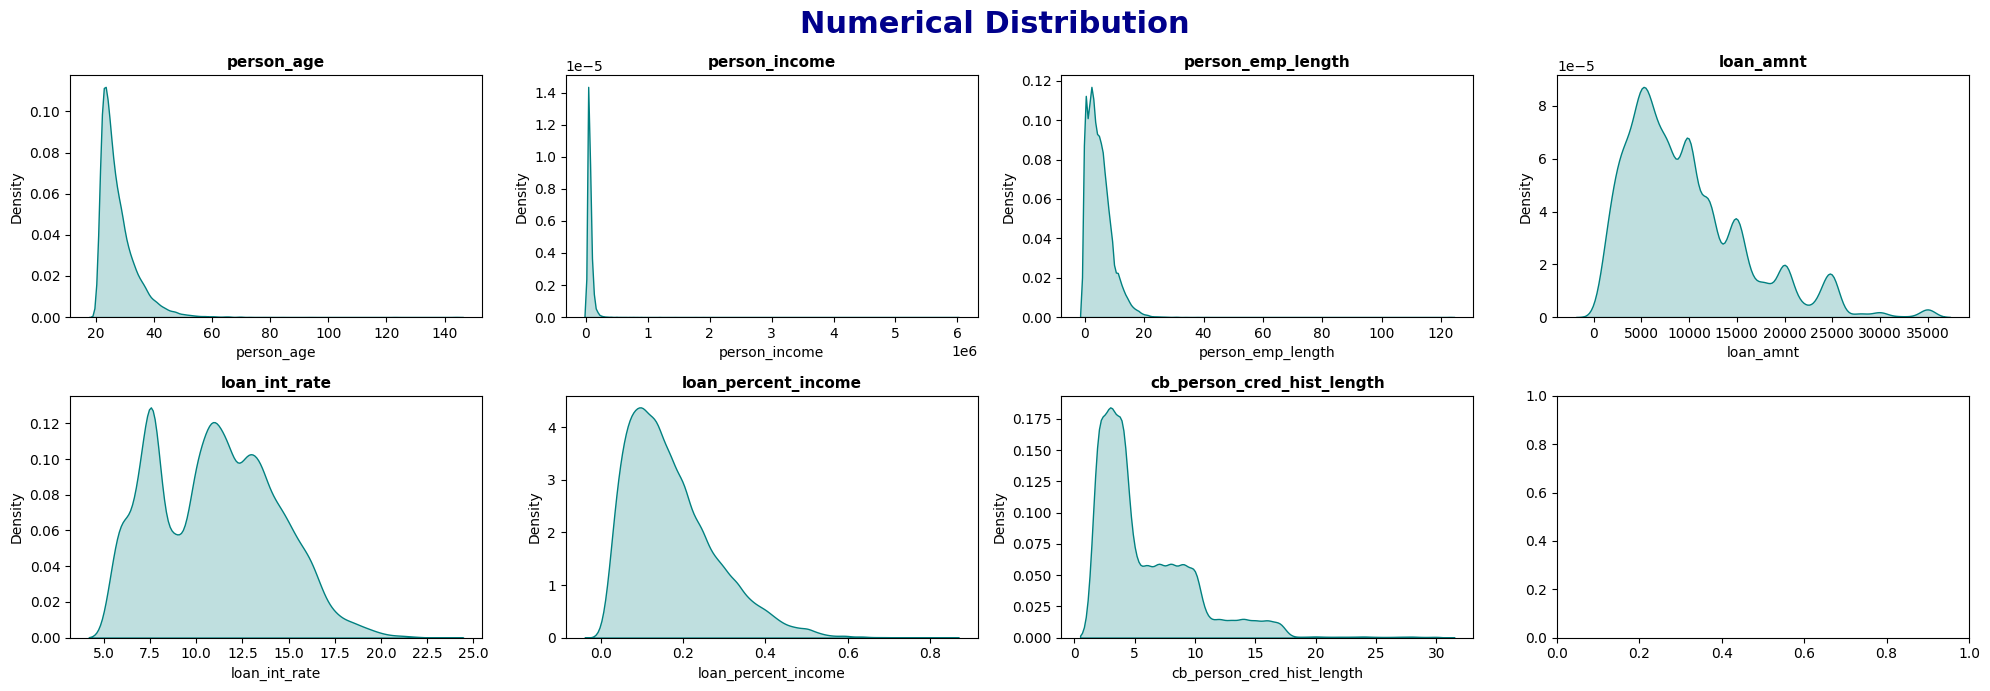

In [12]:
#Extracting numerical columns.
num_cols = x.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(2,4,figsize=(20,7))
plt.suptitle('Numerical Distribution',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(num_cols):
  sns.kdeplot(x = x[cols],fill=True,ax = axes[i],color='teal')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

**Inferance**:
1. **Missing Values**:

-  For feature `person_emp_length` missing vlaues(~2.7%) < 5%  we can drop them.
- For feature `person_int_rate` missing values (~9.56%) > 5% We impute , since it's distribution is skew we applying medium is resonable.
2. **Distribution**:<br>
- `person_age`: Right-skewed distribution with peak around 22-30 years. Most borrowers are young adults. The long tail indicates fewer older borrowers. May benefit from log transformation.
- `person_income`: Highly right-skewed with extreme outliers (up to 6 million). Most incomes are clustered near 0-100k. These extreme outliers will negatively impact model performance and should be handled (winsorization or log transform).
- `person_emp_length`: Right-skewed with peak near 0-5 years. Most borrowers have shorter employment history. Long tail extends to 120+ years (likely data entry errors). Median imputation is appropriate.
- `loan_amnt`: Multi-modal distribution spread across 0-35,000. Multiple peaks suggest different loan categories/purposes. No extreme outliers but wide range.
loan_int_rate: Bimodal distribution with two distinct peaks (~7-8% and ~12-13%). This suggests two distinct borrower risk groups. Group-wise imputation (by loan_grade) preserves this natural pattern.
- `loan_status`: Moderately imbalanced — Class 0 (~78%) vs Class 1 ( ~22%). Ratio is approximately 3.5:1. Model may become biased toward majority class. Resampling techniques (SMOTE) or class weights recommended.
- `loan_percent_income`: Right-skewed with peak near 0.1-0.2. Most borrowers request loans worth 10-20% of their income. Long tail indicates some borrowers requesting very high loan-to-income ratios (higher risk).
- `cb_person_cred_hist_length`: Right-skewed with peak near 2-5 years. Most borrowers have short credit history. Long tail up to 30 years. Short credit history may correlate with higher default risk.

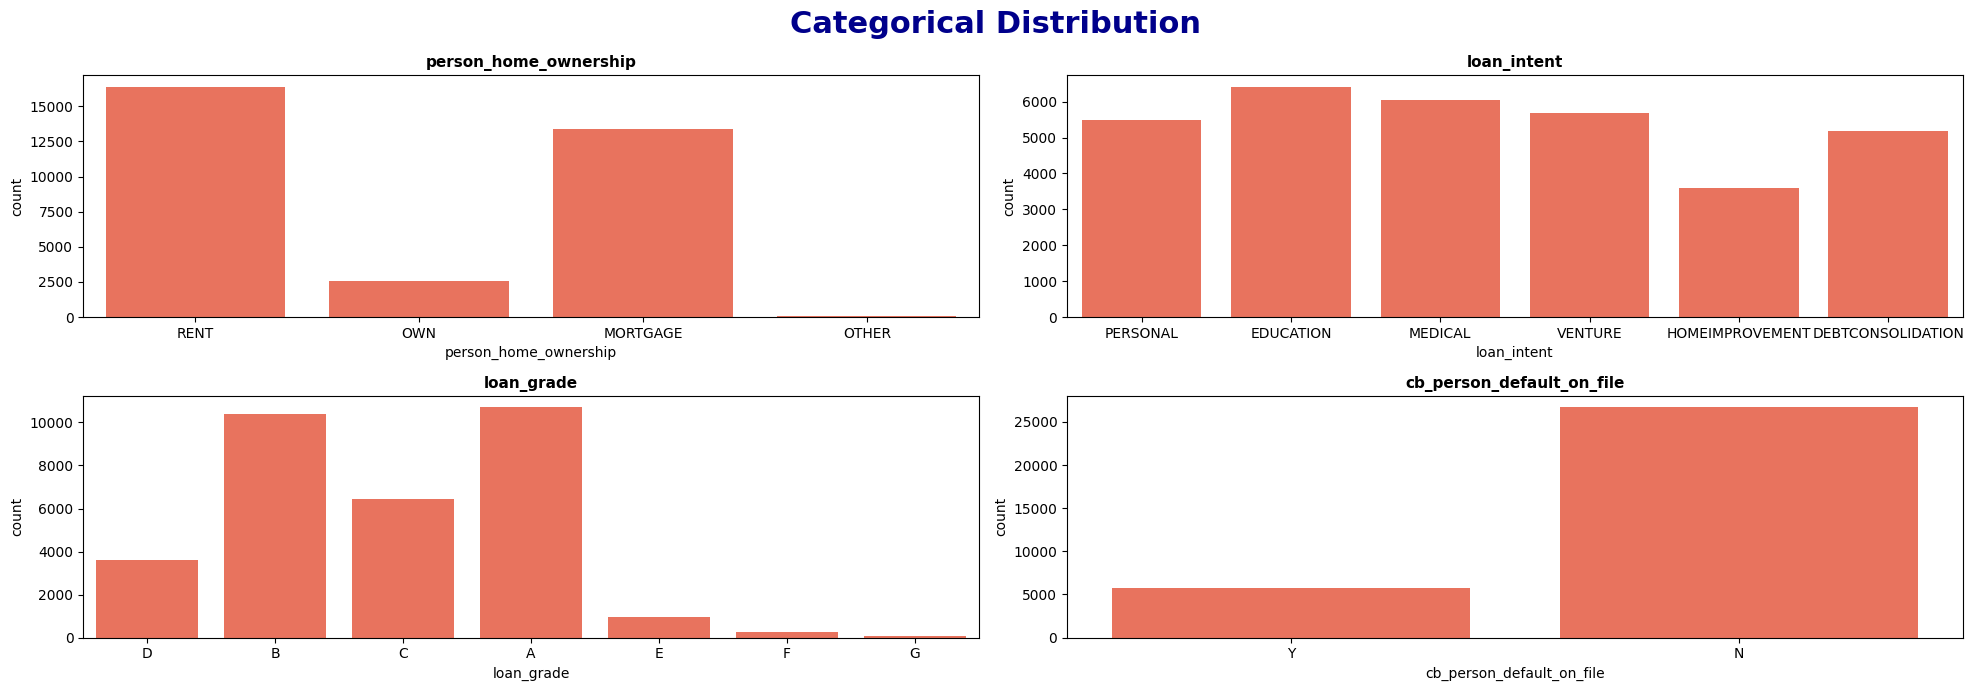

In [13]:
#Extracting categorical columns.
cat_cols = x.select_dtypes(include='object').columns.to_list()
fig , axes = plt.subplots(2,2,figsize=(20,7))
plt.suptitle('Categorical Distribution',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(cat_cols):
  sns.countplot(x = x[cols],fill=True,ax = axes[i],color='tomato')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

**Inference**:
1. `person_home_ownership`:
- RENT is the most common category (~ 16,000 borrowers), followed by MORTGAGE (~12,500).
- OWN has very few borrowers (~2,000), and OTHER is negligible.
- Insight: Most borrowers are renters, which may indicate younger demographics or lower financial stability. Renters and mortgage holders may have different default risks compared to outright owners.
- Encoding Strategy: Use One-Hot Encoding (no inherent order between categories).
2. `loan_intent`:
- Distribution is relatively balanced across categories.
- EDUCATION (~ 6,000) and MEDICAL (~5,800) are the top loan purposes.
- HOMEIMPROVEMENT (~3,000) is the least common.
- Insight: Borrowers take loans for diverse reasons. Education and medical loans may have different repayment behaviors compared to venture or debt consolidation loans.
- Encoding Strategy: Use One-Hot Encoding (nominal categories, no order).
3. `loan_grade`:
- Grade A and Grade B dominate (~10,000 each), representing the majority of loans.
- Grade C (~ 6,000) and Grade D (~3,500) are moderate.
- Grades E, F, G have very few loans (< 1,000 combined).
- Insight: Most borrowers receive lower-risk grades (A, B). Higher-risk grades (E, F, G) are rare, which aligns with lending practices — banks avoid high-risk loans.
- Encoding Strategy: Use Ordinal Encoding (A < B < C < D < E < F < G) because grades have a natural order of risk.
4. `cb_person_default_on_file`:
- N (No previous default) dominates with ~ 24,000 borrowers (~81%).
- Y (Previous default exists) has only ~ 5,500 borrowers (~19%).
- Insight: This feature is imbalanced — most borrowers have clean credit histories. This is a strong predictor for loan_status; borrowers with previous defaults are at significantly higher risk.
- Encoding Strategy: Can Use Ordinal Encoding (binary: Y=1, N=0).

## **Missing Vlaue Handling**

In [14]:
# Using Z-Score method.
data['loan_int_rate'] = data['loan_int_rate'].fillna(data['loan_int_rate'].median())
data.dropna(inplace=True)
print('Missing Value handled Successfully')

Missing Value handled Successfully


In [15]:
print(f'new data shape: {data.shape}')

new data shape: (31529, 12)


## **Outliers Handling**

In [16]:
Q1 = data[num_cols].quantile(0.25)
Q3 = data[num_cols].quantile(0.75)
IQR=Q3-Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
((data[num_cols] < lower_bound) | (data[num_cols] > upper_bound)).sum()

person_age                    1457
person_income                 1459
person_emp_length              852
loan_amnt                     1628
loan_int_rate                   58
loan_percent_income            614
cb_person_cred_hist_length    1113
dtype: int64

In [17]:
# capping
data[num_cols] = np.where(data[num_cols]> upper_bound,upper_bound,
                          np.where(data[num_cols]< lower_bound,lower_bound,data[num_cols]))
print('Outliers capping Successfully!!')

Outliers capping Successfully!!


In [18]:
data[data['person_age']>100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


## **Bivariate analysis**

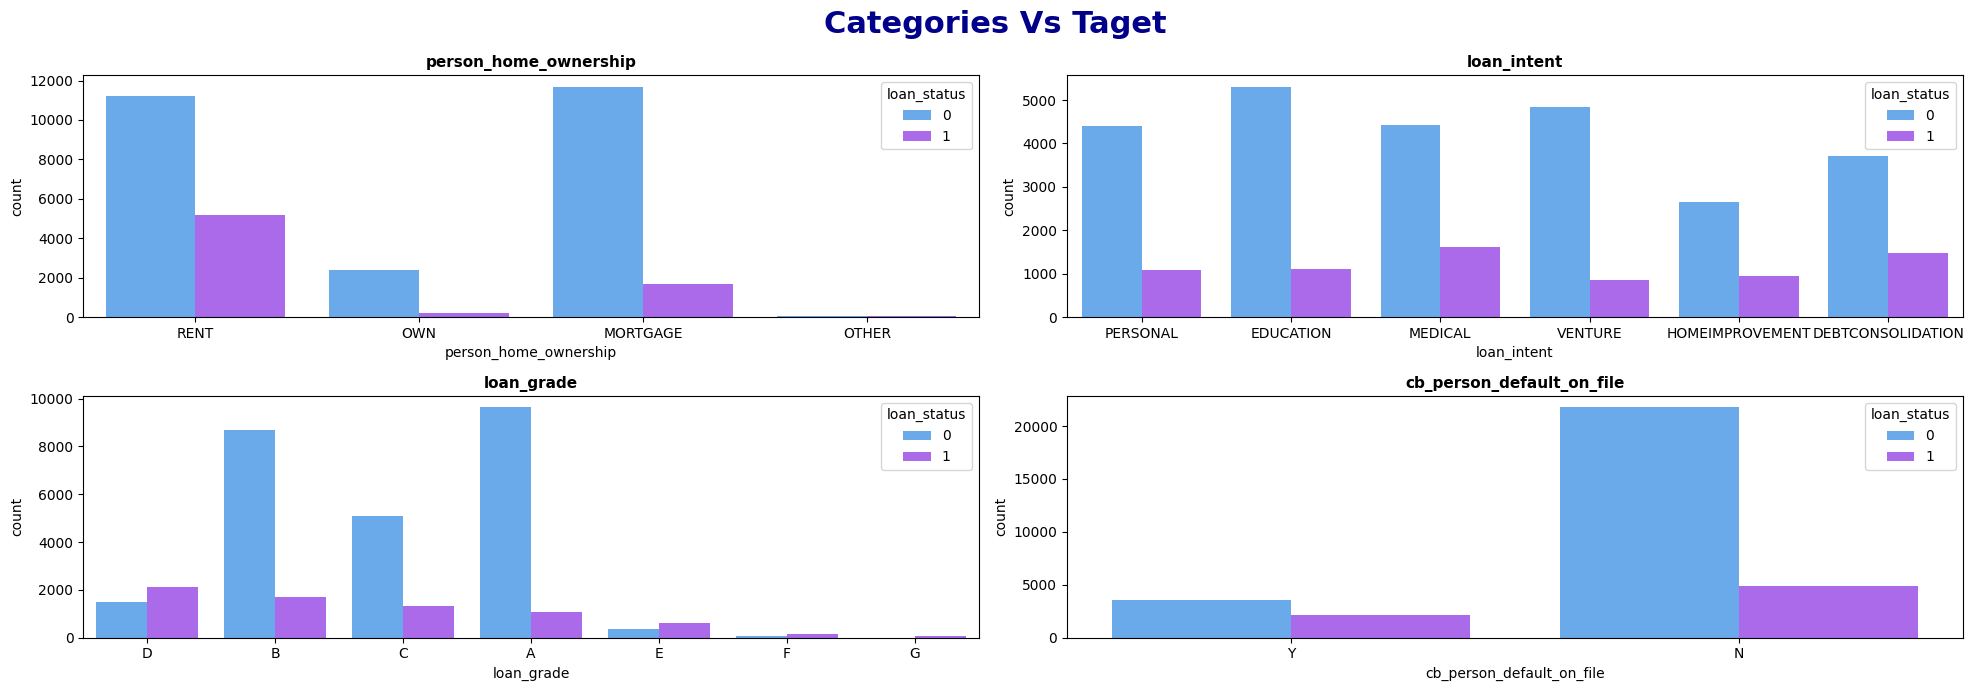

In [19]:
fig , axes = plt.subplots(2,2,figsize=(20,7))
plt.suptitle('Categories Vs Taget',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(cat_cols):
  sns.countplot(x = x[cols],hue=y,fill=True,ax = axes[i],palette='cool')
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

1. person_home_ownership vs loan_status:
- RENT has the highest number of defaults (purple bar is significantly tall). Renters appear to be a higher-risk segment.
- OWN has very few defaults — outright homeowners are the lowest risk group (likely financially stable).
- MORTGAGE has moderate defaults — more than OWN but less than RENT.
- OTHER category has negligible data, may be dropped or merged.
- Insight: Home ownership status is a strong predictor of credit risk. Renters are riskier than owners.
2. loan_intent vs loan_status:
- MEDICAL and DEBTCONSOLIDATION show relatively higher default rates compared to their total counts.
- VENTURE (business loans) also shows notable defaults — business loans carry inherent risk.
- EDUCATION and PERSONAL loans have lower default proportions.
- Insight: Loan purpose matters! Medical and debt consolidation loans may indicate financial stress, leading to higher defaults.
3. loan_grade vs loan_status:
- Clear ordinal trend visible: As grade worsens (A → G), the default rate (purple bar) increases.
- Grade D has the highest default count relative to its total — very risky.
- Grade A has the lowest default rate — safest borrowers.
- Grades E, F, G have very few samples but high default proportions.
- Insight: Loan grade is an excellent predictor of default risk. This confirms that Ordinal Encoding (A=1, B=2, ... G=7) is the correct approach for this feature.
4. cb_person_default_on_file vs loan_status:
- Y (Previous default on file): Very high proportion of defaults — the purple bar is almost half the height of the blue bar.
- N (No previous default): Low default rate — majority of loans are paid back.
- Insight: This is one of the strongest predictors in the dataset. A previous default is a massive red flag for future defaults.

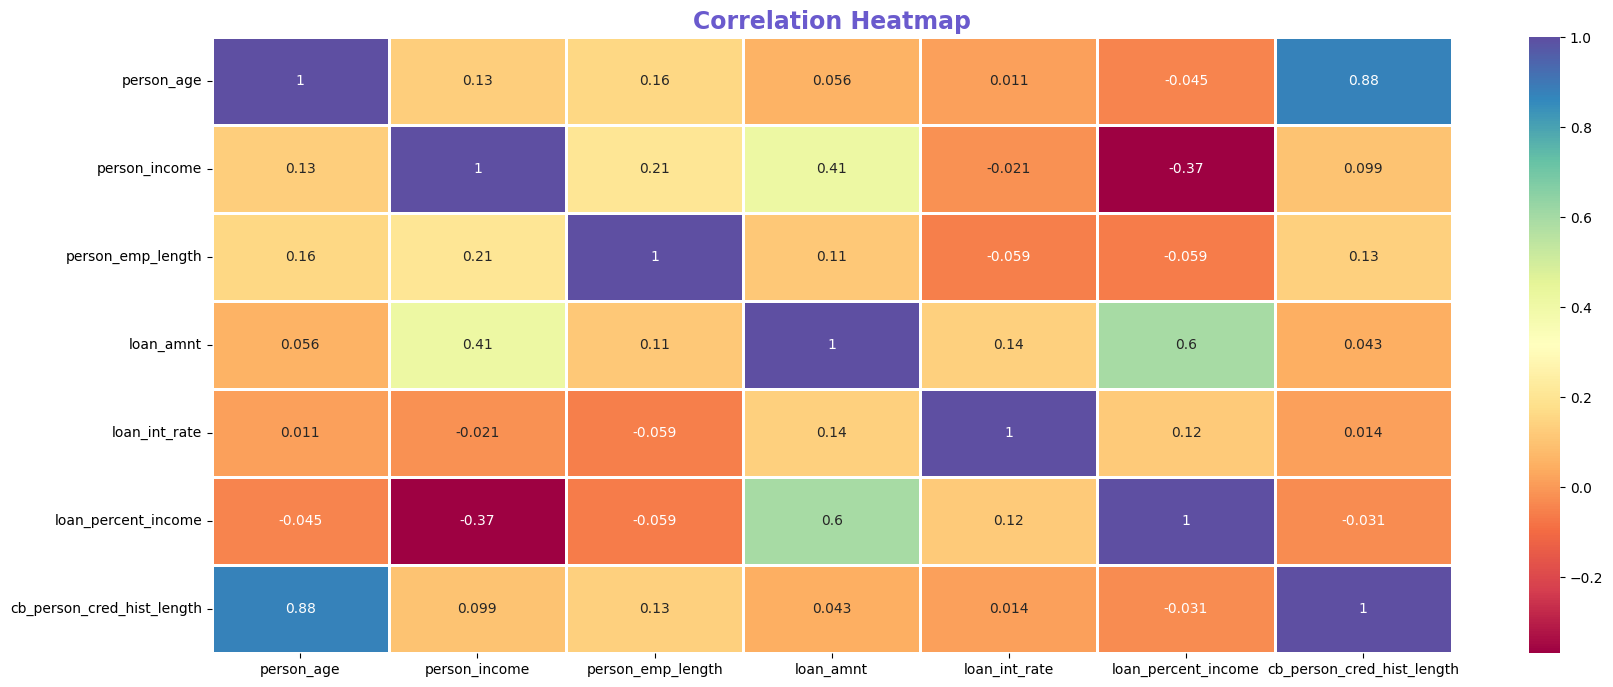

In [20]:

plt.figure(figsize=(20,8))
corr_matrix = data[num_cols].corr()
sns.heatmap(corr_matrix,annot=True,cmap='Spectral',linewidths=0.9)
plt.title('Correlation Heatmap',fontsize=17,fontweight = 'bold',color = 'slateblue')
plt.show()

**Inferance**
1. `Strong Positive Correlation` (Multicollinearity Alert):
-  person_age  ↔  cb_person_cred_hist_length  (0.87): Very strong positive correlation. This makes logical sense — older people naturally have longer credit histories.
-  Problem: This is multicollinearity. Having both features in the model can cause redundancy and instability.
- Action: Consider dropping  person_age  and keeping  cb_person_cred_hist_length  (more directly relevant to credit risk), or use PCA/VIF to decide.
2. `Moderate Positive Correlation`:
-  loan_amnt  ↔  loan_percent_income  (0.59): Moderate correlation. This is expected since  loan_percent_income  is calculated as  loan_amnt / person_income . They share mathematical dependency.
 - person_income  ↔  loan_amnt  (0.40): Higher income borrowers tend to take larger loans. Makes business sense.
3. `Moderate Negative Correlation`:
 - person_income  ↔ loan_percent_income  (-0.35): Higher income borrowers have lower loan-to-income ratios. This is a good sign — wealthier borrowers are less leveraged.
4. `Weak Correlations` (Safe to Keep):
 - person_emp_length  ↔  person_income  (0.19)
 - person_emp_length  ↔  person_age  (0.17)
-  person_age  ↔  person_income  (0.14)
-  loan_int_rate  ↔  loan_amnt  (0.14)
- All other correlations are below 0.15 — negligible.
5. `Near-Zero Correlations` (Independent Features):
-  person_income  ↔  loan_int_rate  (-0.006)
-  loan_int_rate  ↔  cb_person_cred_hist_length  (0.014)
- These features are independent of each other — good for model diversity.

In [21]:
## VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()
vif_data["feature"] = num_cols
vif_data["VIF"] = [variance_inflation_factor(data[num_cols].values, i) for i in range(len(num_cols))]
vif_data

,feature,VIF
0,person_age,4.350979
1,person_income,4.248292
2,person_emp_length,1.070285
3,loan_amnt,5.708691
4,loan_int_rate,1.032991
5,loan_percent_income,5.423566
6,cb_person_cred_hist_length,4.298084


**Inferance**
- All VIF values < 5 (Within acceptable limits.)

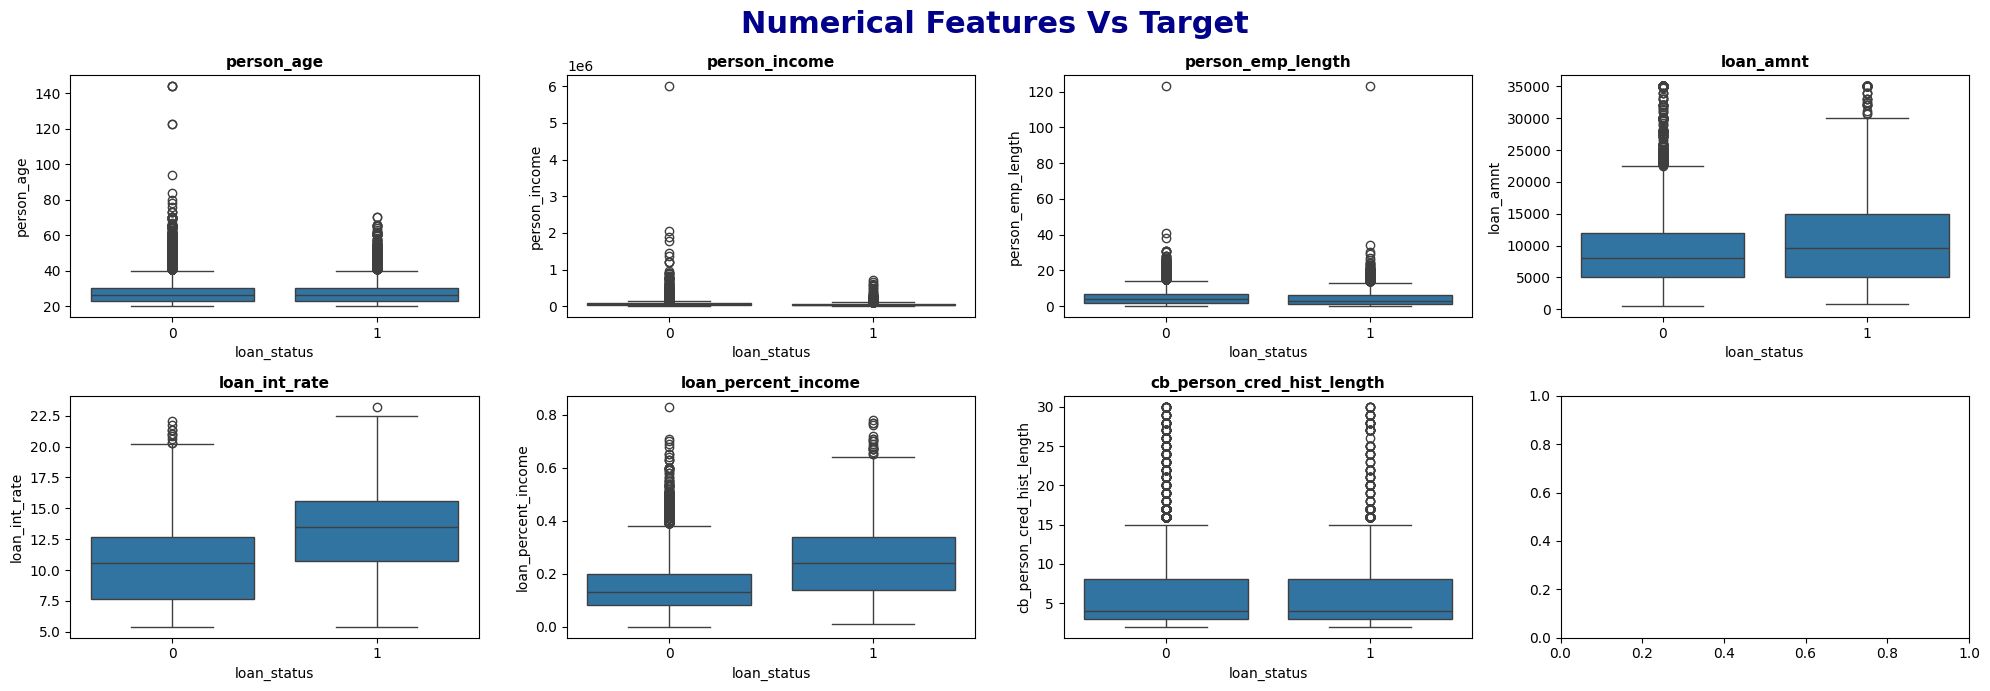

In [22]:
num_cols = x.select_dtypes(include='number').columns.to_list()
fig , axes = plt.subplots(2,4,figsize=(20,7))
plt.suptitle('Numerical Features Vs Target',fontsize=22,fontweight='bold',color='darkblue')
axes = axes.flatten()
for i ,cols in enumerate(num_cols):
  sns.boxplot(y = x[cols],x=y,ax = axes[i])
  axes[i].set_title(f'{cols}',fontsize = 11,fontweight='bold')
plt.tight_layout()
plt.show()

- (loan_status ) — Boxplot Analysis (Post-Outlier Capping)
Context: Since extreme outliers and inconsistent values (e.g.,  person_age  = 144,  person_income  = 6,000,000) have been capped/removed, the boxplots now accurately reflect the true distribution and separation between the two classes.
1.  loan_int_rate  (Strongest Predictor ):
Observation: There is a very clear separation between the classes. The median interest rate for defaulters (Class 1) is significantly higher (~12.5%) compared to non-defaulters (Class 0, ~10%).
Insight: Even after cleaning the data, interest rate remains the most powerful numerical differentiator. Banks correctly price risk by charging higher rates to borrowers more likely to default.
2.  loan_percent_income  (Strong Predictor ):
Observation: Defaulters have a noticeably higher median loan-to-income ratio (~ 0.25) compared to non-defaulters (~0.15). The upper whisker for Class 1 extends much higher.
Insight: Borrowers taking loans that consume a large portion of their income are under higher financial stress, making them more prone to default.
3.  loan_amnt  (Moderate Predictor):
Observation: The median loan amount for defaulters (~ 10,000) is slightly higher than for non-defaulters (~8,000).
Insight: Larger loans carry slightly higher risk, but the separation is not as distinct as the interest rate or income ratio.
4.  cb_person_cred_hist_length  &  person_emp_length  (Moderate/Weak Predictors):
Observation: Non-defaulters (Class 0) show slightly higher median values for both credit history length and employment length compared to defaulters.
Insight: Stability (longer job tenure and longer credit history) is associated with lower default risk, though the overlap between the two classes is significant.
5.  person_age  &  person_income  (Weak Predictors):
Observation: With the extreme outliers removed, the boxplots for age and income show massive overlap between Class 0 and Class 1. The medians are nearly identical.
Insight: Raw age and raw income alone are poor predictors of default. A 25-year-old and a 40-year-old with the same income have similar baseline risk. This confirms that derived features like  loan_percent_income  are much more valuable than raw income.

## **Splitting data in train and testing**

In [23]:
from sklearn.model_selection import  train_test_split
from sklearn.compose import  ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [24]:
x_train , x_test ,y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [25]:
x_train.shape,x_test.shape

((25932, 11), (6484, 11))

## **Handle Class Imbalance**
- Since class are Moderately imbalance we can use `Class-Weights`

In [26]:
# 0 -> No
# 1 -> 1 Yes
neg , pos = np.bincount(y_train)
scale_weights = neg/pos

In [27]:
num_cols = x_train.select_dtypes(include='number').columns.to_list()
cat_cols = x_train.select_dtypes(include='object').columns.to_list()

### **Preproccessing for Logistic Regression (Baseline)**

In [28]:
preprocessor_lr = ColumnTransformer(
    transformers=[
        # Pipeline -> For Numerical Cols.
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('Scaler',StandardScaler())
        ]),num_cols),
        # Pipeline -> Categorical Cols.
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])

In [29]:
from sklearn.linear_model import LogisticRegression

### **Preproccessing for XG BOOST & RandomForest**

In [30]:
# No scaling required.
preprocessor_xg_rf = ColumnTransformer(
    transformers=[
        # Pipeline -> For Numerical Cols.
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median'))
        ]),num_cols),
        # Pipeline -> Categorical Cols.
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy='most_frequent')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])

## **Evaluation Helper**
- Building a common functions to check any model's performance.
- It will show accuracy,precision ,recall,F1 score and more.
- It will also show a confusion matrix and precision-recall curve.

In [31]:
# we to evaluate logistic model and XGB model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve
def evaluate_model(model_name:str , model,X_test,y_test,threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold != None:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)


  # metrices:
  accuracy = accuracy_score(y_test,y_pred) # Overall Model's Performance
  precision = precision_score(y_test,y_pred) # Of the ones I picked, how many are correctly  right ?
  recall = recall_score(y_test,y_pred)# Out of everything that was really there, how much did we manage to find.
  f1 = f1_score(y_test,y_pred)# hormonic mean of precision and recall.


  # confusion matrix:
  cm = confusion_matrix(y_test,y_pred)
  classification_rep = classification_report(y_test,y_pred)
  sns.heatmap(cm)
  print(f'{model_name} Performance:')
  print(f'Accuracy: {accuracy:.3f}')
  print(f'Precision: {precision:.3f}')
  print(f'Recall: {recall:.3f}')
  print(f'F1: {f1:.3f}')
  if threshold != None: 
      print(f'Best theshold: {threshold:.2f}')
  print()
  print(classification_rep)
  print()

  # ploting confusions matrix
  sns.heatmap(cm,annot=True,fmt='d')
  plt.title(f'{model_name} Confusion Matrix')
  plt.xlabel('Predicted Labels')
  plt.ylabel('True Labels')
  plt.show()
  print()

  # ploting Precision Recall curve
  precisons , recall , threshold = precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recall,precisons,color='red')
  plt.title(f'{model_name} Precision-Recall Curve')
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.show()

## **Stratified Cross-Validation**
- One single train-test split may not be reliable.
- We split the training data into five folds instead.
- Each fold keeps the same default vs rapid ratio.
- we check the model's score across all folds.

In [32]:
from sklearn.model_selection import StratifiedKFold,cross_validate

In [33]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {'roc_auc':'roc_auc',
           'accuracy':'accuracy',
           'precision':'precision',
           'recall':'recall',
           'f1':'f1'
           }

## **Baseline Model - Logistic Regression**

In [34]:
lr_model = Pipeline(steps=[
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight="balanced"))])

In [35]:
lr_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [36]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline(steps=[
    ('preprocessor',preprocessor_xg_rf),
    ('classifier',RandomForestClassifier(class_weight="balanced"))
])

In [37]:
rf_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced'))])

In [38]:
# XGB Model
from xgboost import XGBClassifier
xgb_model= Pipeline(steps=[
    ('preprocessor',preprocessor_xg_rf),
    ('classifier',XGBClassifier(max_depth = 5,learning_rate=0.1,scale_pos_weight=scale_weights))
])

In [39]:
xgb_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [40]:
for cv_name , pipe in [("Logistic Regression" ,lr_model),
                       ("Random Forest",rf_model),
                  ('XGBoost',xgb_model)]:
                  cv_results = cross_validate(pipe,x_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
                  print(cv_name)
                  print()
                  print(f'ROC-AUC:{cv_results["test_roc_auc"].mean():.3f}')
                  print(f'Accuracy:{cv_results["test_accuracy"].mean():.3f}')
                  print(f'Precision:{cv_results["test_precision"].mean():.3f}')
                  print(f'Recall:{cv_results["test_recall"].mean():.3f}')
                  print(f'F1:{cv_results["test_f1"].mean():.3f}')
                  print('='*50)

Logistic Regression

ROC-AUC:0.871
Accuracy:0.810
Precision:0.547
Recall:0.779
F1:0.643
Random Forest

ROC-AUC:0.929
Accuracy:0.932
Precision:0.970
Recall:0.710
F1:0.820
XGBoost

ROC-AUC:0.939
Accuracy:0.904
Precision:0.777
Recall:0.788
F1:0.783


Logistic Regression Performance:
Accuracy: 0.815
Precision: 0.556
Recall: 0.772
F1: 0.646

              precision    recall  f1-score   support

           0       0.93      0.83      0.87      5066
           1       0.56      0.77      0.65      1418

    accuracy                           0.82      6484
   macro avg       0.74      0.80      0.76      6484
weighted avg       0.85      0.82      0.82      6484




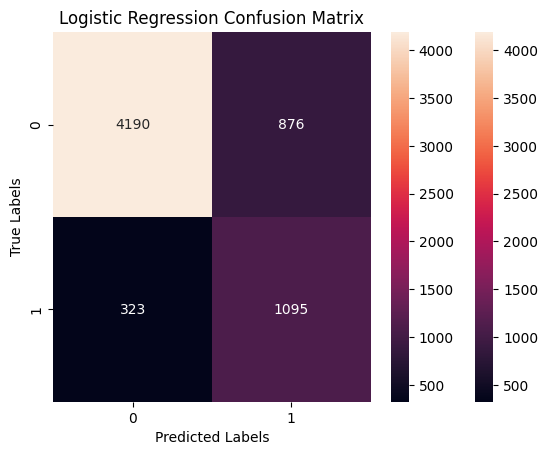

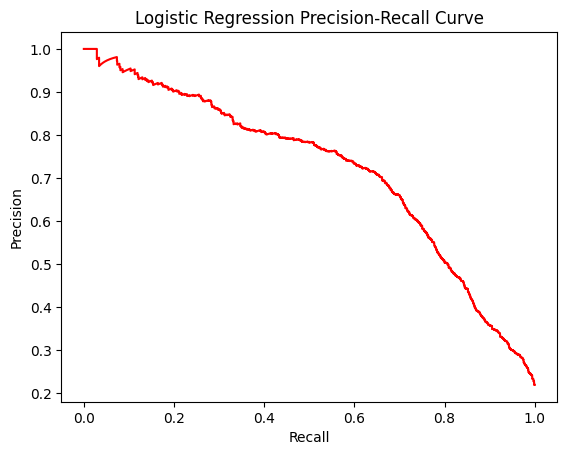

In [41]:
evaluate_model('Logistic Regression',lr_model,x_test,y_test)

Random Forest Performance:
Accuracy: 0.933
Precision: 0.970
Recall: 0.714
F1: 0.823

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5066
           1       0.97      0.71      0.82      1418

    accuracy                           0.93      6484
   macro avg       0.95      0.85      0.89      6484
weighted avg       0.94      0.93      0.93      6484




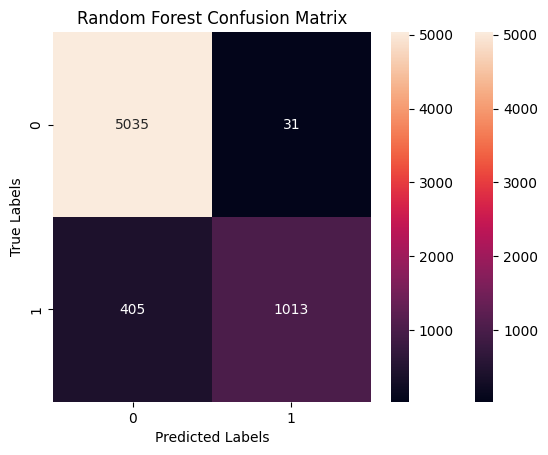

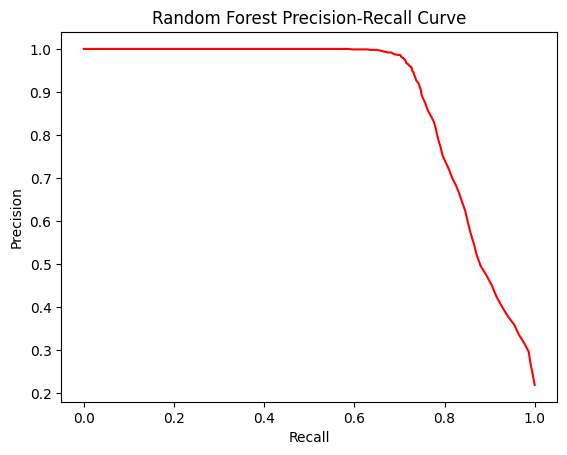

In [42]:
evaluate_model('Random Forest',rf_model,x_test,y_test)

XGBoost Performance:
Accuracy: 0.910
Precision: 0.800
Recall: 0.782
F1: 0.791

              precision    recall  f1-score   support

           0       0.94      0.95      0.94      5066
           1       0.80      0.78      0.79      1418

    accuracy                           0.91      6484
   macro avg       0.87      0.86      0.87      6484
weighted avg       0.91      0.91      0.91      6484




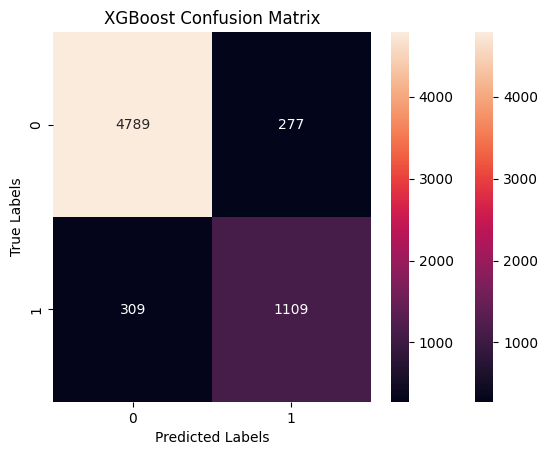

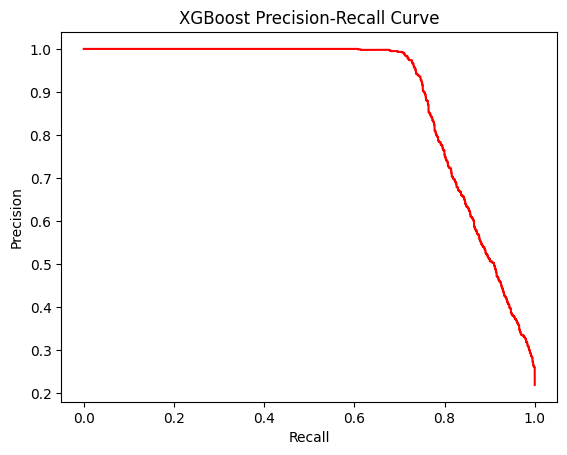

In [43]:
# Evaluate xgboost model
evaluate_model('XGBoost',xgb_model,x_test,y_test)

📊 Project Inference & Strategic Conclusion
1. Model Performance Trade-off
Our evaluation reveals a distinct behavioral difference between the two top-performing models on the credit risk dataset:
Random Forest demonstrates exceptional precision (97.3%) with a very low false positive rate (28). It acts conservatively: when it flags a customer as "risky," it is almost always correct. However, it misses more actual risky customers (lower recall: 71.2%).
XGBoost achieves higher recall (78.8%), successfully identifying more truly risky customers, but at the cost of a higher false positive rate (277) and lower precision (77.7%).
2. Business Impact Analysis
In a credit risk context, model selection is not just about the highest accuracy; it is about minimizing the most expensive error:
If the business priority is to minimize financial loss from loan defaults (where the cost of a False Negative is high), XGBoost is the preferred baseline, as it casts a wider net to catch risky applicants.
If the business priority is to maximize revenue and avoid unfairly rejecting good customers (where the cost of a False Positive is high), Random Forest is superior due to its highly reliable positive predictions.

## **Hyperperameter Tuning**

In [44]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform,loguniform

In [45]:
'''
Tuning Random Forest
Goal: Increasing recall without much compromising with precision.
'''
param_grid_rf = {
    'classifier__n_estimators': randint(200,600),
    'classifier__max_depth': [None, 5, 8, 10, 12, 15],
    'classifier__min_samples_split': randint(2, 15),
    'classifier__min_samples_leaf': randint(1, 15),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__bootstrap': [True, False],
    'classifier__class_weight':['balanced',None,'balanced_subsample'],
    'classifier__criterion':['gini','entropy'],
}


In [46]:
random_search_rf = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid_rf,
    n_iter=30,
    scoring="average_precision",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [47]:
random_search_rf.fit(x_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(str...
                                        'classifier__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7cdee2278e10>,
                                        'classifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7cdee2278b90>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7cdee2f97cb0>},
                   random_state=42, scoring='average_precision', verbose=1)

In [48]:
random_search_rf.best_params_

{'classifier__bootstrap': False,
 'classifier__class_weight': 'balanced',
 'classifier__criterion': 'entropy',
 'classifier__max_depth': None,
 'classifier__max_features': 'log2',
 'classifier__min_samples_leaf': 1,
 'classifier__min_samples_split': 11,
 'classifier__n_estimators': 251}

In [49]:
y_pred = random_search_rf.predict(x_test)

Random forest Performance:
Accuracy: 0.929
Precision: 0.911
Recall: 0.747
F1: 0.821

              precision    recall  f1-score   support

           0       0.93      0.98      0.96      5066
           1       0.91      0.75      0.82      1418

    accuracy                           0.93      6484
   macro avg       0.92      0.86      0.89      6484
weighted avg       0.93      0.93      0.93      6484




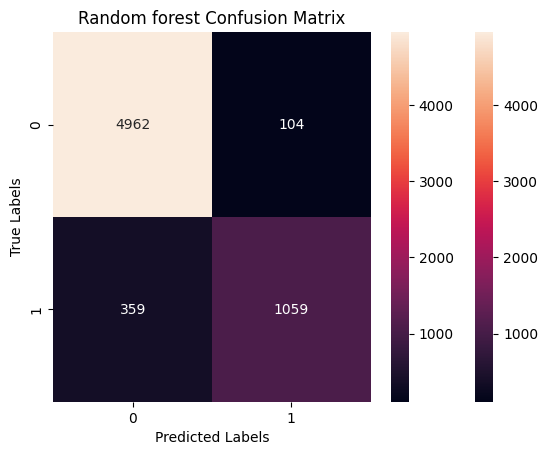

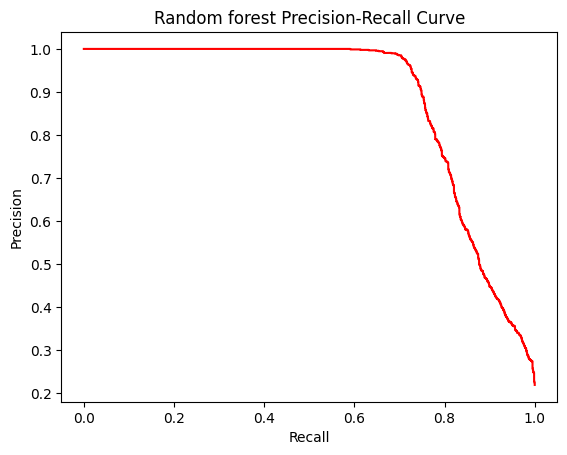

In [50]:
# after hyperparameter tuning.
evaluate_model('Random forest',random_search_rf,x_test,y_test)

In [51]:
"""
Tuning XGBoost
Goal: Minimizing errors"""
param_dist_xgb = {
    "classifier__n_estimators": randint(200, 800),

    "classifier__learning_rate": loguniform(0.01, 0.2),

    "classifier__max_depth": randint(3, 8),

    "classifier__min_child_weight": randint(1, 10),

    "classifier__subsample": uniform(0.6, 0.4),

    "classifier__colsample_bytree": uniform(0.6, 0.4),

    "classifier__gamma": uniform(0, 0.5),

    "classifier__reg_alpha": loguniform(1e-3, 10),

    "classifier__reg_lambda": loguniform(1, 20),

    "classifier__scale_pos_weight": [2.5,3.0,3.16,3.5,4.0]
}
# lower gamma -> more splits ->complex tree -> higher overfitting risk
# higher gamma -> lower splits -> simpler tree -> lower overfitting risk

In [52]:
random_search_xgb= RandomizedSearchCV(
                   xgb_model,
                   param_dist_xgb,
                   n_iter = 30,
                   cv= cv,
                   scoring = 'average_precision',
                   verbose = 1,
                   n_jobs = -1)

In [53]:
random_search_xgb.fit(x_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2daab10>,
                                        'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2a9e7b0>,
                                        'classifier__scale_pos_weight': [2.5,
                                                                         3.0,
                                                                         3.16,
                                                                         3.5,
                                                                         4.0],
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2b91f90>},
                   scoring='average_precision', verbose=1)

In [54]:
random_search_xgb.best_params_

{'classifier__colsample_bytree': np.float64(0.9188336133143314),
 'classifier__gamma': np.float64(0.4650833107186894),
 'classifier__learning_rate': np.float64(0.038718708197787846),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 556,
 'classifier__reg_alpha': np.float64(0.0041805266295689295),
 'classifier__reg_lambda': np.float64(1.7283679094252966),
 'classifier__scale_pos_weight': 2.5,
 'classifier__subsample': np.float64(0.8906855399187756)}

In [55]:
y_pred = random_search_xgb.predict(x_test)

XGBoost Performance:
Accuracy: 0.932
Precision: 0.910
Recall: 0.766
F1: 0.832

              precision    recall  f1-score   support

           0       0.94      0.98      0.96      5066
           1       0.91      0.77      0.83      1418

    accuracy                           0.93      6484
   macro avg       0.92      0.87      0.89      6484
weighted avg       0.93      0.93      0.93      6484




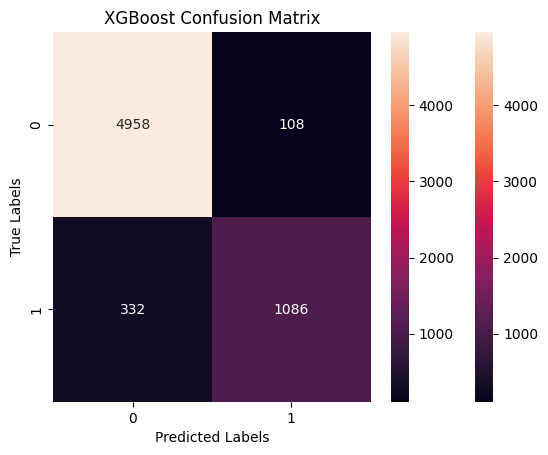

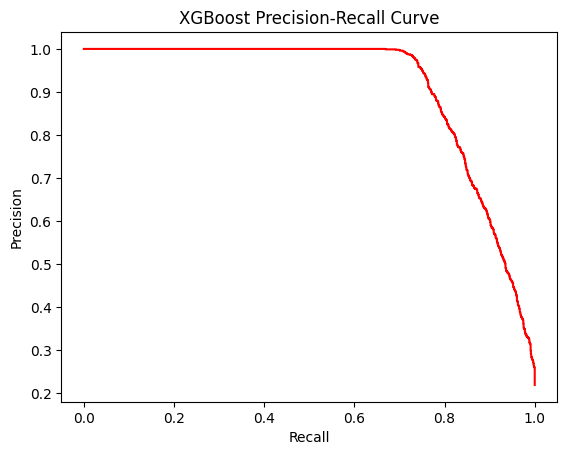

In [56]:
# after hyperparameter tuning.
evaluate_model('XGBoost',random_search_xgb,x_test,y_test)

## **Optimizing the Classification Threshold**
- The model give a probability not dirct yes or No.
- We decide a cut-off point to turn into a decision.
- We check different cut -off points and pick the best one.

Random Forest Model  Performance:
Accuracy: 0.933
Precision: 0.962
Recall: 0.723
F1: 0.826
Best theshold: 0.59

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5066
           1       0.96      0.72      0.83      1418

    accuracy                           0.93      6484
   macro avg       0.94      0.86      0.89      6484
weighted avg       0.94      0.93      0.93      6484




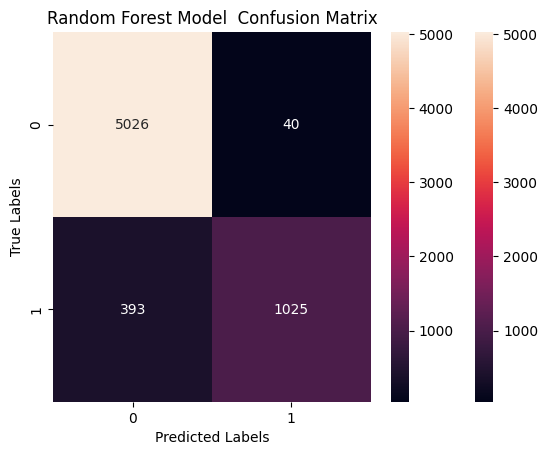

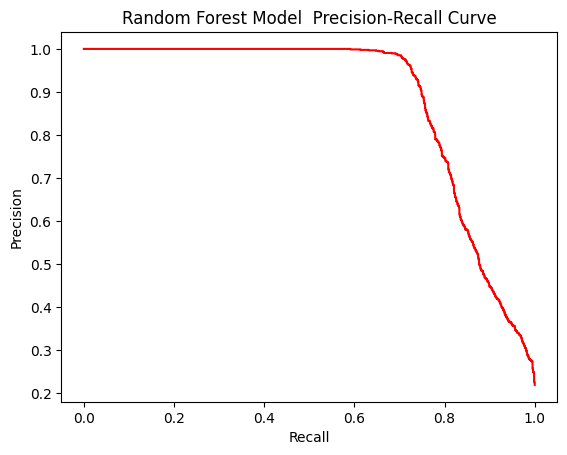

In [57]:
# for random forest
# get the probability  for class 1 from Random Forest
prob = random_search_rf.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
best_threshold = threshold[np.argmax(f1)]
# evaluate the Random Forest model .
evaluate_model('Random Forest Model ',random_search_rf,x_test,y_test,threshold=best_threshold)


XGB Model  Performance:
Accuracy: 0.938
Precision: 0.972
Recall: 0.739
F1: 0.840
Best theshold: 0.66

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5066
           1       0.97      0.74      0.84      1418

    accuracy                           0.94      6484
   macro avg       0.95      0.87      0.90      6484
weighted avg       0.94      0.94      0.94      6484




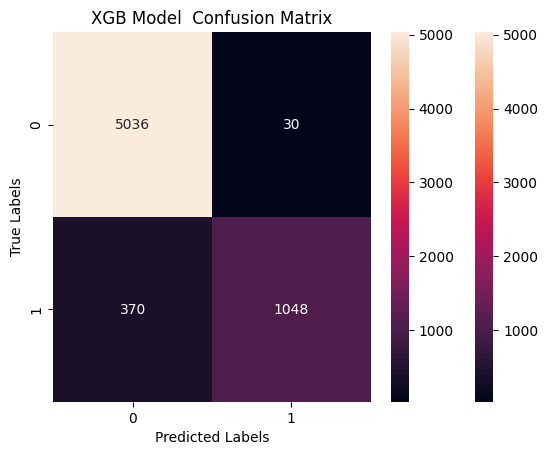

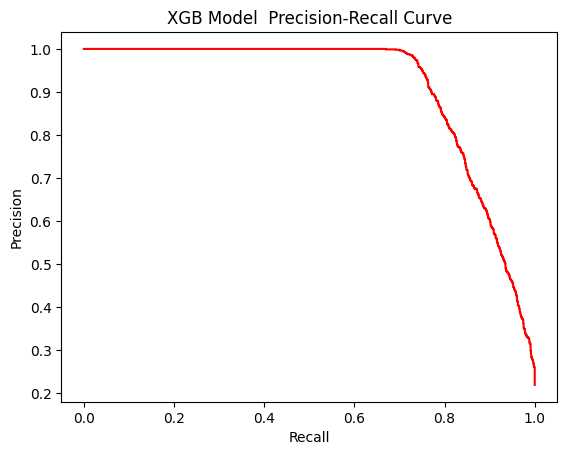

In [58]:
# For XGB
# get the probability  for class 1 from XGB
prob = random_search_xgb.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
best_threshold = threshold[np.argmax(f1)]
# evaluate the XGB model .
evaluate_model('XGB Model ',random_search_xgb,x_test,y_test,threshold=best_threshold)

## **Probability Calibration**

In [59]:
#1 . Calibrated XGB model
from sklearn.calibration import  CalibratedClassifierCV,calibration_curve
from sklearn.frozen import FrozenEstimator
calibrated_xgb = CalibratedClassifierCV(
    estimator = FrozenEstimator(random_search_xgb),
    method='sigmoid',
    cv = 10
    )
calibrated_xgb.fit(x_train,y_train)

CalibratedClassifierCV(cv=10,
                       estimator=FrozenEstimator(estimator=RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                                                                              estimator=Pipeline(steps=[('preprocessor',
                                                                                                         ColumnTransformer(transformers=[('num',
                                                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                                                           SimpleImputer(strategy='median'))]),
                                                                                                                                          ['person_age',
                                                                                                                                           'person_income',
                                                                                                                                           'person_emp_length',
                                                                                                                                           'loan_amnt',...
                                                                                                   'classifier__reg_alpha': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2daab10>,
                                                                                                   'classifier__reg_lambda': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2a9e7b0>,
                                                                                                   'classifier__scale_pos_weight': [2.5,
                                                                                                                                    3.0,
                                                                                                                                    3.16,
                                                                                                                                    3.5,
                                                                                                                                    4.0],
                                                                                                   'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7cdee2b91f90>},
                                                                              scoring='average_precision',
                                                                              verbose=1)))

XGB Model  Performance:
Accuracy: 0.938
Precision: 0.972
Recall: 0.739
F1: 0.840
Best theshold: 0.87

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      5066
           1       0.97      0.74      0.84      1418

    accuracy                           0.94      6484
   macro avg       0.95      0.87      0.90      6484
weighted avg       0.94      0.94      0.94      6484




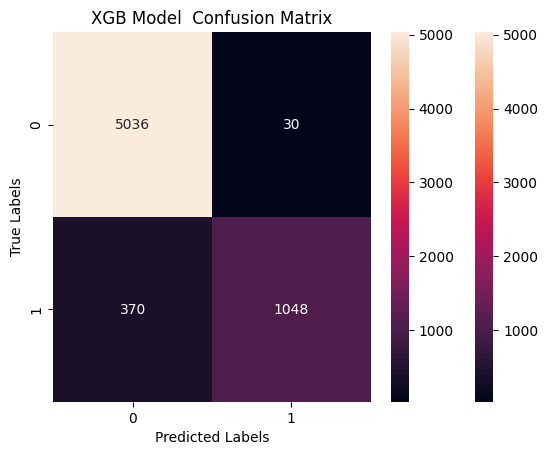

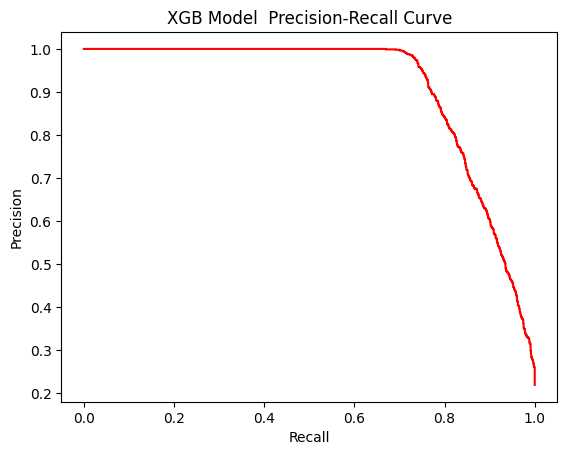

In [60]:
# For XGB
# get the probability  for class 1 from XGB
calibrated_prob = calibrated_xgb.predict_proba(x_test)[:,1]
# for each threshold calculate Precision and recall
precision , recall , threshold = precision_recall_curve(y_test,calibrated_prob)
# calculate f1 score for each threshold
f1 = 2*(precision * recall)/(precision + recall + 10e-9)
# get the threshold that produces the highest f1 -score
new_threshold = threshold[np.argmax(f1)]
# evaluate the XGB model .
evaluate_model('XGB Model ',calibrated_xgb,x_test,y_test,threshold=new_threshold)

In [61]:
#2. Get prob.
uncalibrated_prob = random_search_xgb.predict_proba(x_test)[:,1]
calibrated_prob = calibrated_xgb.predict_proba(x_test)[:,1]

In [62]:
#3. Create callibration curves.
actual_uncal,predicted_uncal= calibration_curve(y_test,uncalibrated_prob,n_bins=15)
actual_cal,predicted_cal = calibration_curve(y_test,calibrated_prob,n_bins=15)

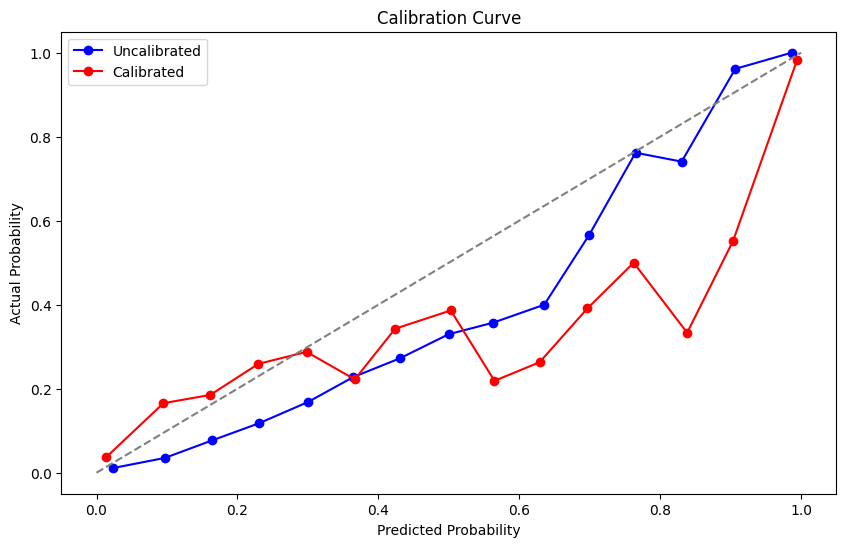

In [63]:
#4. plot
plt.figure(figsize=(10,6))
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='o',
    linestyle='-',
    color='blue',
    label='Uncalibrated'
)
plt.plot(
    predicted_cal,
    actual_cal,
    marker='o',
    linestyle='-',
    color='red',
    label='Calibrated'
)
plt.plot([0,1],[0,1],linestyle='--',color='gray')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Probability')
plt.title('Calibration Curve')
plt.legend()

XGBoost Performance:
Accuracy: 0.931
Precision: 0.900
Recall: 0.771
F1: 0.830

              precision    recall  f1-score   support

           0       0.94      0.98      0.96      5066
           1       0.90      0.77      0.83      1418

    accuracy                           0.93      6484
   macro avg       0.92      0.87      0.89      6484
weighted avg       0.93      0.93      0.93      6484




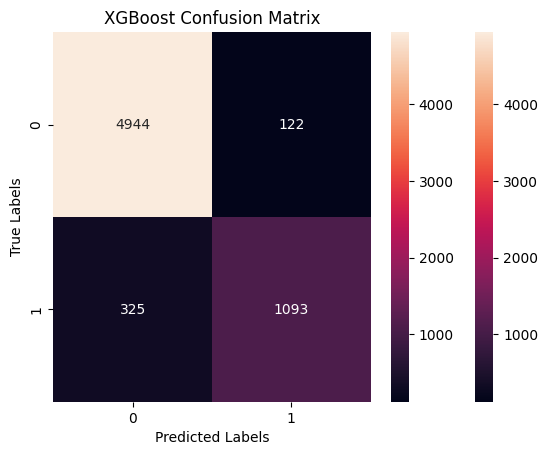

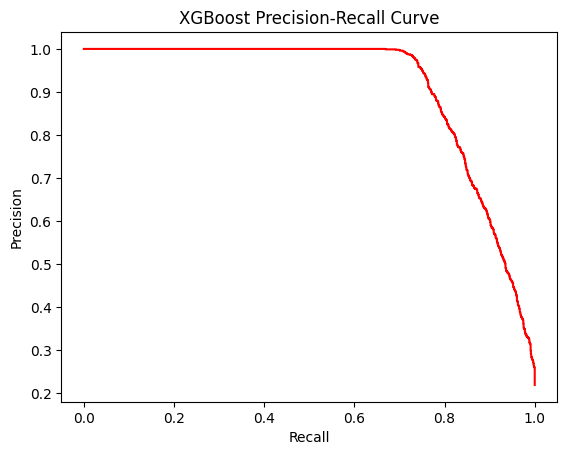

In [64]:
evaluate_model('XGBoost',calibrated_xgb,x_test,y_test)

# **SHAP Interpretation - Global & Local**

In [65]:
import shap
#1. Get the trained XGB classifier model out of the pipeline.
xgb_classifier = xgb_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [66]:
#2. Transform x_test using the same preprocessing used for training.
x_test_transformed = xgb_model.named_steps['preprocessor'].transform(x_test)

In [67]:
#3. Get features names after one-hot-encoding,so plots are readable.
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

In [68]:
#4. Convert to a data frame for cleaner SHAP plots
x_test_df = pd.DataFrame(x_test_transformed,columns=feature_names)

In [73]:
#5. create SHAP explainer built for tree-based model.
explainer = shap.TreeExplainer(xgb_classifier)

In [74]:
#6. Calculate shap values for every row in the test set
shap_values = explainer.shap_values(x_test_df)

## **Global Explanation**

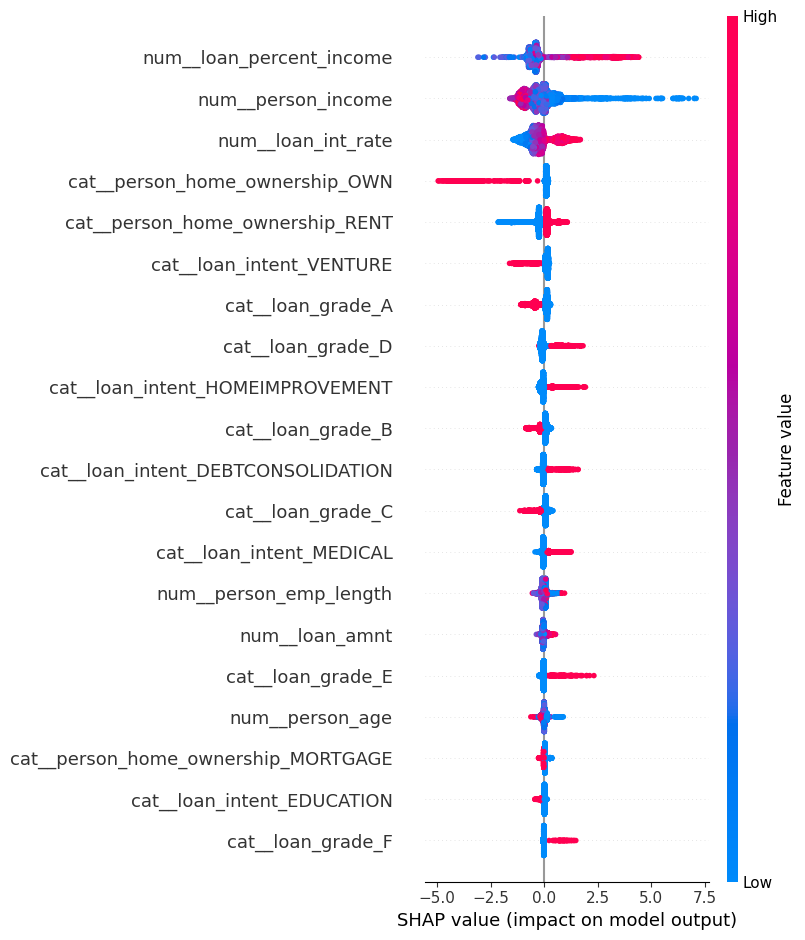

In [75]:
shap.summary_plot(shap_values,x_test_df)

## **Local Explaination**

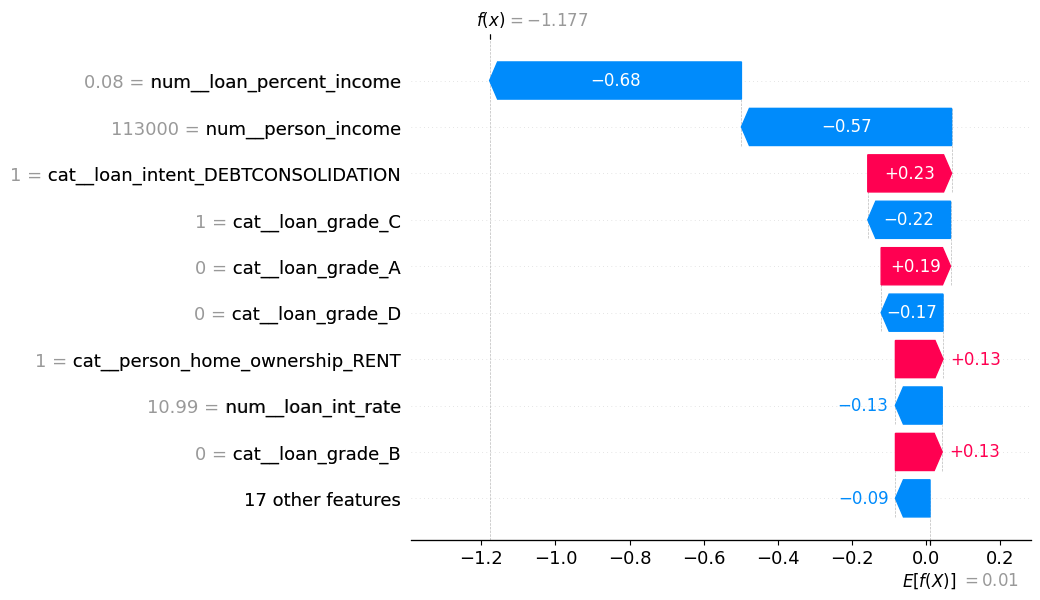

In [76]:
#1. pick one row to explain , e.g the 5th applicant in the test set.
row_index = 5
#2. Draw a waterfall plot showing how each features pushed the prediction up or down.
plt.figure(figsize=(10,6))
shap.waterfall_plot(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data= x_test_df.iloc[row_index],
        feature_names= feature_names
    ))

## **Analyzing False Positives & False Negatives.**

In [77]:
# get prediction from best peforming model on the test set
y_pred = random_search_xgb.predict(x_test)

In [85]:
# create a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [86]:
# identify FP : model pred 1 , but actual 0
false_positives = result_df[(result_df['predicted'] == 1) & (result_df['actual'] == 0)]
# identify FN : model pred 0 , but actual 1
false_negatives = result_df[(result_df['predicted'] == 0) & (result_df['actual'] == 1)]

In [87]:
print(f'False Positives: {len(false_positives)}')
print(f'False Negatives: {len(false_negatives)}')

False Positives: 108
False Negatives: 332


## **Saving Best Model**

In [88]:
import joblib
joblib.dump(calibrated_xgb,'xgb_model.joblib')

['xgb_model.joblib']

In [89]:
joblib.dump(new_threshold,'best_threshold')

['best_threshold']

In [90]:
%config Completer.use_jedi = False